# Tarea 2 · Parte 2 — Evaluación de modelos y extracción estructurada

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio peruanos en un archivo de texto estructurado y buscable? Aquí se mide **qué tan bien** lo hacen los modelos y **a qué costo**.

**Reglas que se siguieron**

1. **Muestra sin datos nuevos.** De los corpus de la Parte 1 se sortearon 10 documentos (3 impresos, 3 fotos, 4 manuscritos) y 10 clips (distintas fuentes y condiciones de grabación). El sorteo es estratificado, con semilla 2026 (`muestra_evaluacion.py`), y se hizo solo con metadatos, sin mirar resultados de OCR ni de ASR.
2. **Referencias manuales.** Las 20 transcripciones son manuales, hechas por la autora (`datos/raw/referencias_manuales.xlsx`, fuera de Git porque se transcribió literal, con nombres). En los clips largos se transcribieron **los primeros 60 s**, y ese mismo recorte es el que reciben todos los modelos.
3. **Mismos archivos para todos los modelos**, con configuraciones fijadas en `evaluacion.py` **antes** de calcular ninguna métrica. No se ajustó ningún parámetro mirando los resultados.
4. **Misma normalización** para referencias y predicciones: sin marcas `[HABLANTE_N]` ni `[PERSONA_N]`, minúsculas, sin puntuación y con los espacios colapsados.
5. Las métricas se calculan sobre los textos **sin seudonimizar**, para que el reemplazo de nombres no altere el error. Todo lo que se publica (CSV, tablas, app) va seudonimizado.

**Modelos comparados**

| Modalidad | Línea base (sin ajuste) | Alternativos |
|---|---|---|
| Documentos | PaddleOCR 3.7 · PP-OCRv6_medium, `lang="es"`, CPU | Tesseract 5.5 · LSTM, `lang="spa"`, `--psm 3`, CPU |
| Audio | faster-whisper `small`, int8, CPU, VAD on | Qwen3-ASR 0.6B (Alibaba, no es Whisper), GPU del Mac (MPS) · faster-whisper large-v3-turbo (el modelo de la Parte 1), CPU |

In [1]:
import json
import os
import re
import time
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import soundfile as sf

os.environ.setdefault("ASR_HILOS", "8")
import asr
import evaluacion as ev
import llm

pio.renderers.default = "notebook_connected+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 520
pio.templates.default = "plotly_white"
pd.set_option("display.max_colwidth", 80)
DATOS = Path("datos")

for paquete in ["paddleocr", "pytesseract", "faster-whisper", "transformers", "torch", "jiwer"]:
    print(f"{paquete:<15} {version(paquete)}")
print("tesseract       ", __import__("pytesseract").get_tesseract_version())

paddleocr       3.7.0
pytesseract     0.3.13
faster-whisper  1.2.1
transformers    5.20.2
torch           2.14.1
jiwer           4.0.0
tesseract        5.5.2


## 1 · Muestra de evaluación y referencias manuales

In [2]:
muestra = pd.read_csv(DATOS / "muestra_evaluacion.csv")
referencias = ev.leer_referencias()
assert set(muestra["id"]) == set(referencias["id"]) and (referencias["texto_referencia"].str.len() > 0).all()

muestra["caracteres_ref"] = muestra["id"].map(dict(zip(referencias["id"], referencias["texto_referencia"].map(ev.normalizar).str.len())))
muestra["palabras_ref"] = muestra["id"].map(dict(zip(referencias["id"], referencias["texto_referencia"].map(lambda t: len(ev.normalizar(t).split())))))
print(f"{len(referencias)} referencias manuales completas · "
      f"{muestra.loc[muestra.modalidad == 'documento', 'caracteres_ref'].sum()} caracteres de documentos · "
      f"{muestra.loc[muestra.modalidad == 'audio', 'palabras_ref'].sum()} palabras de audio")
muestra[["id", "modalidad", "estrato", "recorte", "caracteres_ref", "palabras_ref"]]

20 referencias manuales completas · 8214 caracteres de documentos · 1051 palabras de audio


,id,modalidad,estrato,recorte,caracteres_ref,palabras_ref
0,doc_005,documento,impreso,página completa,1570,265
1,doc_006,documento,impreso,página completa,1328,227
2,doc_004,documento,impreso,página completa,2400,435
3,doc_013,documento,foto,página completa,405,67
4,doc_014,documento,foto,página completa,308,50
5,doc_012,documento,foto,página completa,218,36
6,doc_024,documento,manuscrito,página completa,602,95
7,doc_020,documento,manuscrito,página completa,296,44
8,doc_025,documento,manuscrito,página completa,315,51
9,doc_022,documento,manuscrito,página completa,772,120


In [3]:
# La normalización, aplicada igual a referencias y predicciones
ejemplo = "[HABLANTE_1] ¿Qué expectativas tienen, señora?  [HABLANTE_2] [PERSONA_8], ¡que gane el Perú!"
print("antes:  ", ejemplo)
print("después:", ev.normalizar(ejemplo))

antes:   [HABLANTE_1] ¿Qué expectativas tienen, señora?  [HABLANTE_2] [PERSONA_8], ¡que gane el Perú!
después: qué expectativas tienen señora que gane el perú


## 2 · Ejecución de los modelos sobre la muestra

Cada celda corre un modelo sobre **sus 10 archivos** y guarda las predicciones crudas en `datos/raw/evaluacion/predicciones.csv`. En documentos se mide la latencia en segundos por documento; en audio, el **factor de tiempo real** (segundos de cómputo ÷ segundos de audio; menos de 1 es más rápido que el tiempo real). El hardware es el mismo para todos: una Mac con Apple Silicon. Los modelos de CPU usan 8 hilos y Qwen3-ASR usa la GPU integrada (MPS).

In [4]:
# Línea base OCR: la misma configuración de la Parte 1, sin personalización.
t0 = time.perf_counter()
r = ev.correr("PaddleOCR PP-OCRv6 (base)")
print(f"PaddleOCR PP-OCRv6 (base): {len(r)} archivos en {time.perf_counter() - t0:.0f} s (incluye cargar el modelo)")
r[["id", "segundos"] + (["duracion_seg"] if r["modalidad"].iloc[0] == "audio" else [])].T

PaddleOCR PP-OCRv6 (base): 10 archivos en 285 s (incluye cargar el modelo)


,40,41,42,43,44,45,46,47,48,49
id,doc_005,doc_006,doc_004,doc_013,doc_014,doc_012,doc_024,doc_020,doc_025,doc_022
segundos,26.18,60.17,44.83,36.46,19.65,16.72,20.96,10.45,16.13,22.31


In [5]:
# OCR alternativo: Tesseract 5 (LSTM), paradigma distinto, sin detector aprendido.
t0 = time.perf_counter()
r = ev.correr("Tesseract 5 (spa)")
print(f"Tesseract 5 (spa): {len(r)} archivos en {time.perf_counter() - t0:.0f} s (incluye cargar el modelo)")
r[["id", "segundos"] + (["duracion_seg"] if r["modalidad"].iloc[0] == "audio" else [])].T

Tesseract 5 (spa): 10 archivos en 12 s (incluye cargar el modelo)


,40,41,42,43,44,45,46,47,48,49
id,doc_005,doc_006,doc_004,doc_013,doc_014,doc_012,doc_024,doc_020,doc_025,doc_022
segundos,1.74,2.35,1.74,1.11,1.2,0.86,0.86,0.6,1.08,0.39


In [6]:
# Línea base ASR del enunciado: faster-whisper small en CPU.
t0 = time.perf_counter()
r = ev.correr("faster-whisper small (CPU)")
print(f"faster-whisper small (CPU): {len(r)} archivos en {time.perf_counter() - t0:.0f} s (incluye cargar el modelo)")
r[["id", "segundos"] + (["duracion_seg"] if r["modalidad"].iloc[0] == "audio" else [])].T

faster-whisper small (CPU): 10 archivos en 238 s (incluye cargar el modelo)


,40,41,42,43,44,45,46,47,48,49
id,clip_022,clip_023,clip_021,clip_015,clip_001,clip_008,clip_005,clip_003,clip_012,clip_016
segundos,5.6,6.08,5.83,37.22,31.14,27.18,33.18,46.19,34.9,8.57
duracion_seg,10.92,8.53,7.08,60.0,60.0,60.0,60.0,60.0,60.0,60.0


In [7]:
# El modelo de la Parte 1 sobre los mismos recortes.
t0 = time.perf_counter()
r = ev.correr("faster-whisper large-v3-turbo (CPU)")
print(f"faster-whisper large-v3-turbo (CPU): {len(r)} archivos en {time.perf_counter() - t0:.0f} s (incluye cargar el modelo)")
r[["id", "segundos"] + (["duracion_seg"] if r["modalidad"].iloc[0] == "audio" else [])].T

faster-whisper large-v3-turbo (CPU): 10 archivos en 408 s (incluye cargar el modelo)


,40,41,42,43,44,45,46,47,48,49
id,clip_022,clip_023,clip_021,clip_015,clip_001,clip_008,clip_005,clip_003,clip_012,clip_016
segundos,13.87,15.17,14.95,62.92,42.96,55.35,58.56,57.42,61.02,22.47
duracion_seg,10.92,8.53,7.08,60.0,60.0,60.0,60.0,60.0,60.0,60.0


In [8]:
# ASR alternativo que no es Whisper: Qwen3-ASR 0.6B en la GPU del Mac.
t0 = time.perf_counter()
r = ev.correr("Qwen3-ASR 0.6B (MPS)")
print(f"Qwen3-ASR 0.6B (MPS): {len(r)} archivos en {time.perf_counter() - t0:.0f} s (incluye cargar el modelo)")
r[["id", "segundos"] + (["duracion_seg"] if r["modalidad"].iloc[0] == "audio" else [])].T

W1025 21:31:28.433000 2278 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

Loading weights:  72%|███████▏  | 439/611 [00:00<00:00, 4387.68it/s]

Loading weights: 100%|██████████| 611/611 [00:00<00:00, 4668.58it/s]

Qwen3-ASR 0.6B (MPS): 10 archivos en 80 s (incluye cargar el modelo)


,40,41,42,43,44,45,46,47,48,49
id,clip_022,clip_023,clip_021,clip_015,clip_001,clip_008,clip_005,clip_003,clip_012,clip_016
segundos,0.74,0.68,0.54,10.78,9.9,10.03,11.22,12.49,11.84,2.81
duracion_seg,10.92,8.53,7.08,60.0,60.0,60.0,60.0,60.0,60.0,60.0


## 3 · Métricas: CER en documentos y WER en audio

- **CER** (*character error rate*) = (sustituciones + borrados + inserciones de caracteres) ÷ caracteres de la referencia.
- **WER** (*word error rate*): lo mismo, pero contando palabras.

El valor de cada modelo es **agregado sobre toda la muestra**: errores totales ÷ tamaño total de las referencias. Así un documento corto no pesa lo mismo que uno largo. Se calcula con `jiwer`.

In [9]:
predicciones = pd.read_csv(ev.PREDICCIONES)
err = ev.errores(predicciones, referencias)
tabla = ev.resumen(err)
orden = list(ev.MODELOS)
tabla["orden"] = tabla["modelo"].map(orden.index)
tabla = tabla.sort_values(["modalidad", "orden"], ascending=[False, True]).drop(columns="orden")
tabla.round(3)

,modalidad,modelo,papel,metrica,valor,segundos,segundos_por_archivo,factor_tiempo_real
0,documento,PaddleOCR PP-OCRv6 (base),línea base,CER,0.168,273.86,27.386,NaN
1,documento,Tesseract 5 (spa),alternativo,CER,0.364,11.93,1.193,NaN
2,audio,faster-whisper small (CPU),línea base,WER,0.389,235.89,23.589,0.528
3,audio,faster-whisper large-v3-turbo (CPU),modelo de la Parte 1,WER,0.369,404.69,40.469,0.906
4,audio,Qwen3-ASR 0.6B (MPS),alternativo,WER,0.411,71.03,7.103,0.159


### Línea base

In [10]:
base = tabla[tabla["papel"] == "línea base"].set_index("modalidad")
print(f"Línea base OCR  · PaddleOCR (sin ajuste)        CER = {base.loc['documento', 'valor']:.3f} "
      f"({base.loc['documento', 'segundos_por_archivo']:.1f} s por documento)")
print(f"Línea base ASR  · faster-whisper small en CPU   WER = {base.loc['audio', 'valor']:.3f} "
      f"(factor de tiempo real {base.loc['audio', 'factor_tiempo_real']:.2f})")

Línea base OCR  · PaddleOCR (sin ajuste)        CER = 0.168 (27.4 s por documento)
Línea base ASR  · faster-whisper small en CPU   WER = 0.389 (factor de tiempo real 0.53)


### Error por archivo

Cada celda es el error de un modelo en un archivo. Así se ve **dónde** falla cada uno, no solo cuánto.

In [11]:
etiqueta = dict(zip(muestra["id"], muestra["id"] + " · " + muestra["estrato"]))
por_archivo = err.assign(error=np.where(err["modalidad"] == "documento", err["cer"], err["wer"]),
                         archivo=err["id"].map(etiqueta))
display(por_archivo[por_archivo.modalidad == "documento"].pivot_table(index="archivo", columns="modelo", values="error").round(2))
display(por_archivo[por_archivo.modalidad == "audio"].pivot_table(index="archivo", columns="modelo", values="error").round(2))

modelo,PaddleOCR PP-OCRv6 (base),Tesseract 5 (spa)
archivo,,
doc_004 · impreso,0.13,0.15
doc_005 · impreso,0.10,0.38
doc_006 · impreso,0.13,0.17
doc_012 · foto,0.02,0.15
doc_013 · foto,0.02,0.15
doc_014 · foto,0.66,0.67
doc_020 · manuscrito,0.16,0.44
doc_022 · manuscrito,0.24,0.99
doc_024 · manuscrito,0.34,0.72


modelo,Qwen3-ASR 0.6B (MPS),faster-whisper large-v3-turbo (CPU),faster-whisper small (CPU)
archivo,,,
clip_001 · calle o marcha,0.30,0.27,0.28
clip_003 · conferencia de prensa,0.23,0.27,0.26
clip_005 · testimonio,0.20,0.18,0.19
clip_008 · testimonio,0.26,0.22,0.23
clip_012 · entrevista de estudiante (UNMSM),0.42,0.34,0.37
clip_015 · calle o marcha,0.42,0.33,0.36
clip_016 · fiesta patronal (Áncash),0.92,0.85,0.90
clip_021 · lectura en estudio (OpenSLR 73),0.00,0.00,0.00
clip_022 · lectura en estudio (OpenSLR 73),0.10,0.10,0.10


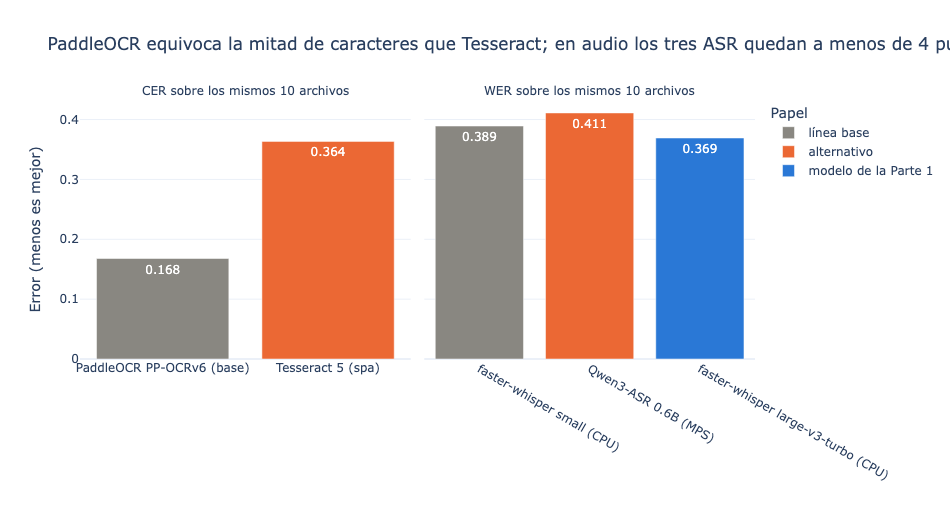

In [12]:
fig = px.bar(tabla, x="modelo", y="valor", color="papel", facet_col="metrica", text_auto=".3f",
             color_discrete_map={"línea base": "#898781", "alternativo": "#eb6834", "modelo de la Parte 1": "#2a78d6"},
             labels={"valor": "Error (menos es mejor)", "modelo": "", "papel": "Papel"},
             title=(f"PaddleOCR equivoca la mitad de caracteres que Tesseract; en audio los tres ASR quedan a menos de "
                    f"{100 * (tabla[tabla.metrica == 'WER']['valor'].max() - tabla[tabla.metrica == 'WER']['valor'].min()):.0f} puntos de WER"))
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1] + " sobre los mismos 10 archivos"))
fig.show()

## 4 · Precisión frente a costo: latencia y factor de tiempo real

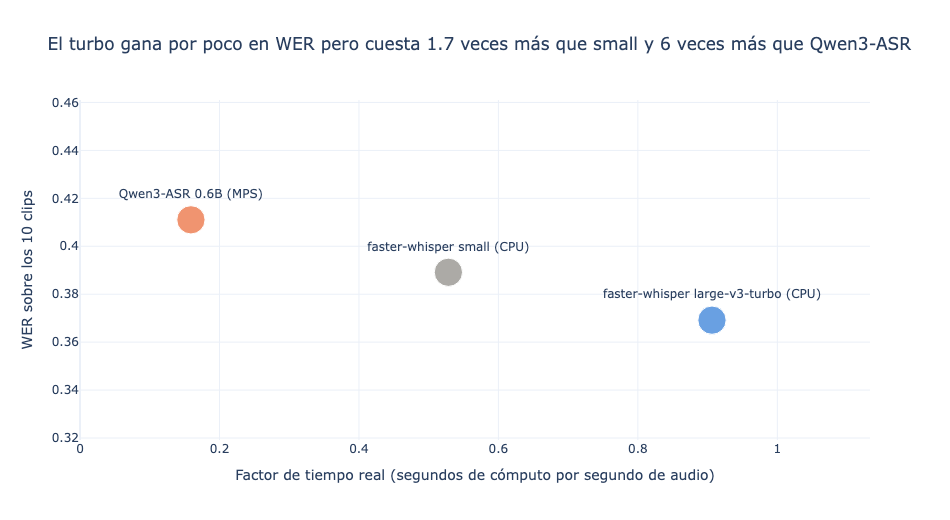

,modelo,CER,segundos por documento
0,PaddleOCR PP-OCRv6 (base),0.168,27.386
1,Tesseract 5 (spa),0.364,1.193


In [13]:
audio = tabla[tabla["modalidad"] == "audio"]
f = audio.set_index("modelo")["factor_tiempo_real"]
fig = px.scatter(audio, x="factor_tiempo_real", y="valor", text="modelo", size=[18] * len(audio),
                 color="papel", color_discrete_map={"línea base": "#898781", "alternativo": "#eb6834", "modelo de la Parte 1": "#2a78d6"},
                 labels={"factor_tiempo_real": "Factor de tiempo real (segundos de cómputo por segundo de audio)",
                         "valor": "WER sobre los 10 clips"},
                 title=(f"El turbo gana por poco en WER pero cuesta {f['faster-whisper large-v3-turbo (CPU)'] / f['faster-whisper small (CPU)']:.1f} veces "
                        f"más que small y {f['faster-whisper large-v3-turbo (CPU)'] / f['Qwen3-ASR 0.6B (MPS)']:.0f} veces más que Qwen3-ASR"))
fig.update_traces(textposition="top center")
fig.update_layout(showlegend=False, xaxis_range=[0, audio["factor_tiempo_real"].max() * 1.25],
                  yaxis_range=[audio["valor"].min() - 0.05, audio["valor"].max() + 0.05])
fig.show()

docs_t = tabla[tabla["modalidad"] == "documento"][["modelo", "valor", "segundos_por_archivo"]]
docs_t.columns = ["modelo", "CER", "segundos por documento"]
docs_t.round(3)

## 5 · Casos difíciles

### 5.1 Documentos: el tipo importa más que el modelo

modelo,PaddleOCR PP-OCRv6 (base),Tesseract 5 (spa)
estrato,,
foto,0.230,0.319
impreso,0.123,0.224
manuscrito,0.259,0.757


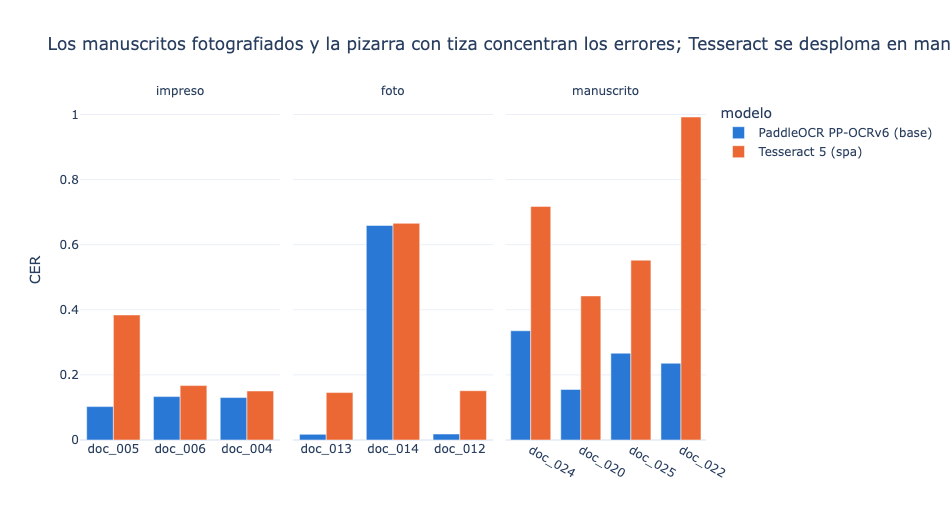

In [14]:
d = por_archivo[por_archivo.modalidad == "documento"].merge(muestra[["id", "estrato"]], on="id")
por_tipo = d.groupby(["estrato", "modelo"]).apply(
    lambda g: (g["cer"] * g["caracteres_ref"]).sum() / g["caracteres_ref"].sum(), include_groups=False).unstack().round(3)
display(por_tipo)
fig = px.bar(d, x="id", y="cer", color="modelo", barmode="group", facet_col="estrato",
             color_discrete_map={"PaddleOCR PP-OCRv6 (base)": "#2a78d6", "Tesseract 5 (spa)": "#eb6834"},
             labels={"cer": "CER", "id": ""},
             title="Los manuscritos fotografiados y la pizarra con tiza concentran los errores; Tesseract se desploma en manuscritos")
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

**Lectura.**
- **Impresos:** los dos OCR funcionan razonablemente. Tesseract se acerca a PaddleOCR en las páginas impresas nítidas (`doc_004`, `doc_006`), pero no en la portada del Mercurio Peruano, de solo 369 px de ancho (`doc_005`).
- **Fotos:** los carteles impresos (`doc_012`, `doc_013`) quedan casi perfectos con PaddleOCR (CER ≈ 0,02). La pizarra de menú escrita con tiza (`doc_014`) es el peor documento para **ambos** modelos (CER ≈ 0,66): palabras pegadas, columnas mezcladas y letra a mano.
- **Manuscritos:** aquí se separan los modelos. PaddleOCR mantiene un CER de 0,16–0,34, mientras Tesseract, entrenado sobre todo con texto impreso, sube a 0,44–0,99. En el papelógrafo (`doc_022`) Tesseract prácticamente no lee nada útil. El detector de líneas aprendido de PaddleOCR es lo que marca la diferencia en letra a mano y en fondos con cuadrícula.

### 5.2 Audio: ruido de calle, música de fiesta y el caso `clip_016`

Para entender los errores se mide, sin cambiar ninguna configuración, **cuánta voz detecta el VAD** (Silero, el mismo filtro que usa faster-whisper) en cada recorte, y el nivel de energía de la señal (RMS).

In [15]:
filas = []
for f in muestra[muestra.modalidad == "audio"].itertuples():
    x, _ = sf.read(f.archivo_evaluacion, dtype="float32")
    voz = sum(b - a for a, b in asr.tramos_de_voz(x))
    filas.append({"id": f.id, "condicion": f.estrato, "duracion_seg": round(len(x) / 16000, 1),
                  "voz_vad_seg": round(voz, 1), "% voz VAD": round(100 * voz / (len(x) / 16000)),
                  "rms": round(float(np.sqrt(np.mean(x ** 2))), 3), "palabras_ref": f.palabras_ref})
vad = pd.DataFrame(filas)
wer_turbo = por_archivo[por_archivo.modelo == "faster-whisper large-v3-turbo (CPU)"].set_index("id")
vad["palabras_turbo"] = vad["id"].map(wer_turbo["palabras_pred"])
vad["WER turbo"] = vad["id"].map(wer_turbo["wer"]).round(2)
vad

,id,condicion,duracion_seg,voz_vad_seg,% voz VAD,rms,palabras_ref,palabras_turbo,WER turbo
0,clip_022,lectura en estudio (OpenSLR 73),10.9,4.5,41,0.041,10,10,0.10
1,clip_023,lectura en estudio (OpenSLR 73),8.5,3.1,36,0.063,12,12,0.08
2,clip_021,lectura en estudio (OpenSLR 73),7.1,4.2,60,0.046,9,9,0.00
3,clip_015,calle o marcha,60.0,46.0,77,0.246,148,125,0.33
4,clip_001,calle o marcha,60.0,49.8,83,0.252,141,125,0.27
5,clip_008,testimonio,60.0,51.0,85,0.090,101,111,0.22
6,clip_005,testimonio,60.0,53.7,90,0.075,133,120,0.18
7,clip_003,conferencia de prensa,60.0,57.8,96,0.172,164,146,0.27
8,clip_012,entrevista de estudiante (UNMSM),60.0,51.1,85,0.167,145,124,0.34
9,clip_016,fiesta patronal (Áncash),60.0,10.6,18,0.246,188,42,0.85


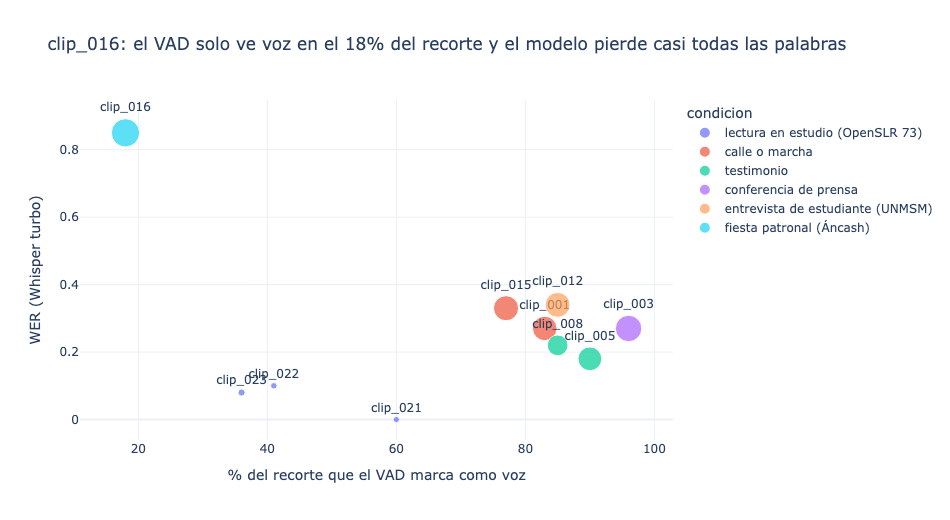

clip_016: 188 palabras en la referencia manual, 42 en la salida del turbo (22%). El error es casi todo borrado de palabras, no confusión.


In [16]:
fig = px.scatter(vad, x="% voz VAD", y="WER turbo", color="condicion", text="id", size="palabras_ref",
                 labels={"% voz VAD": "% del recorte que el VAD marca como voz", "WER turbo": "WER (Whisper turbo)"},
                 title="clip_016: el VAD solo ve voz en el 18% del recorte y el modelo pierde casi todas las palabras")
fig.update_traces(textposition="top center")
fig.show()
c16 = vad.set_index("id").loc["clip_016"]
print(f"clip_016: {c16['palabras_ref']} palabras en la referencia manual, {int(c16['palabras_turbo'])} en la salida del turbo "
      f"({100 * c16['palabras_turbo'] / c16['palabras_ref']:.0f}%). El error es casi todo borrado de palabras, no confusión.")

**Lectura.**
- **Lectura en estudio (OpenSLR):** WER de 0 a 0,10 en los tres modelos. Con voz limpia y un solo hablante, el ASR está prácticamente resuelto.
- **Testimonios y conferencia** (un hablante principal, poco ruido): WER ≈ 0,18–0,27.
- **Calle, marcha y entrevista de estudiante** (ruido de tráfico o multitud, voces que se pisan, micrófono de celular): WER ≈ 0,33–0,42. Los errores son nombres, muletillas y frases cortadas por otra voz.
- **`clip_016`, la fiesta patronal en Áncash**, es el peor caso, con WER de 0,85 a 0,92. Hay música y ruido de fondo (la energía del audio es de las más altas), y el **VAD solo marca como voz 10,6 de los 60 s**, aunque en la referencia manual hay 188 palabras. El mismo filtro que protege a Whisper de inventar frases en el silencio aquí **descarta habla real**, y el modelo nunca la recibe. Qwen3-ASR se usó con el mismo VAD, por eso falla igual. Es un error del preprocesamiento, no del reconocedor. Para audio con música habría que probar otro umbral de VAD o separar la voz de la música antes (por ejemplo, con Demucs). No se hizo aquí para no ajustar parámetros sobre la muestra de evaluación.
- **Quechua de Huaylas (bonificación):** no se evaluó. Los audios en quechua de la Sesión 13 no forman parte de este corpus en español.

## 6 · Tabla comparativa final (base vs. mejorado) y decisión

In [17]:
ELEGIDOS = {"documento": "PaddleOCR PP-OCRv6 (base)", "audio": "faster-whisper large-v3-turbo (CPU)"}
comparativa = tabla.copy()
comparativa["elegido"] = comparativa.apply(lambda f: ELEGIDOS[f["modalidad"]] == f["modelo"], axis=1)
base_val = comparativa[comparativa.papel == "línea base"].set_index("modalidad")["valor"]
comparativa["vs. línea base"] = comparativa.apply(
    lambda f: f"{100 * (f['valor'] - base_val[f['modalidad']]) / base_val[f['modalidad']]:+.0f}%", axis=1)
comparativa["hardware"] = comparativa["modelo"].map(lambda m: "GPU Apple (MPS)" if "MPS" in m else "CPU (8 hilos)")
cols = ["modalidad", "modelo", "papel", "metrica", "valor", "vs. línea base", "segundos_por_archivo", "factor_tiempo_real", "hardware", "elegido"]
comparativa[cols].round(3)

,modalidad,modelo,papel,metrica,valor,vs. línea base,segundos_por_archivo,factor_tiempo_real,hardware,elegido
0,documento,PaddleOCR PP-OCRv6 (base),línea base,CER,0.168,+0%,27.386,NaN,CPU (8 hilos),True
1,documento,Tesseract 5 (spa),alternativo,CER,0.364,+117%,1.193,NaN,CPU (8 hilos),False
2,audio,faster-whisper small (CPU),línea base,WER,0.389,+0%,23.589,0.528,CPU (8 hilos),False
3,audio,faster-whisper large-v3-turbo (CPU),modelo de la Parte 1,WER,0.369,-5%,40.469,0.906,CPU (8 hilos),True
4,audio,Qwen3-ASR 0.6B (MPS),alternativo,WER,0.411,+6%,7.103,0.159,GPU Apple (MPS),False


In [18]:
ftr = tabla[tabla.modalidad == "audio"].set_index("modelo")["factor_tiempo_real"]
turbo, small, qwen = ftr["faster-whisper large-v3-turbo (CPU)"], ftr["faster-whisper small (CPU)"], ftr["Qwen3-ASR 0.6B (MPS)"]
print(f"Factor de tiempo real en esta ejecución: turbo {turbo:.2f} · small {small:.2f} · Qwen3-ASR {qwen:.2f}")
print(f"Small es {turbo / small:.1f} veces más rápido que el turbo; Qwen3-ASR, {turbo / qwen:.1f} veces más rápido")
docs_s = tabla[tabla.modalidad == "documento"].set_index("modelo")["segundos_por_archivo"]
print(f"Tesseract es {docs_s.iloc[0] / docs_s.iloc[1]:.0f} veces más rápido que PaddleOCR por documento")

Factor de tiempo real en esta ejecución: turbo 0.91 · small 0.53 · Qwen3-ASR 0.16
Small es 1.7 veces más rápido que el turbo; Qwen3-ASR, 5.7 veces más rápido
Tesseract es 23 veces más rápido que PaddleOCR por documento


**Decisión para un entorno real** (archivo de documentos y entrevistas peruanas, procesado por lotes en una laptop, sin GPU dedicada).

**Documentos → PaddleOCR (PP-OCRv6).**
- **Precisión:** tiene la mitad del error de Tesseract (CER 0,17 frente a 0,36), y la diferencia es enorme justo en lo difícil: manuscritos y fotos.
- **Costo:** ~28 s por documento en CPU, frente a 1–1,5 s de Tesseract. Para un archivo que se procesa una sola vez, esos segundos valen mucho menos que las horas de corrección manual que ahorra.
- **Cuándo cambiaría:** Tesseract solo tendría sentido como primera pasada rápida sobre impresos limpios, o en un servidor muy limitado.

**Audio → faster-whisper large-v3-turbo**, con faster-whisper small como alternativa económica.
- **Precisión:** el turbo tiene el menor WER (0,37). La ventaja sobre small (0,39) es pequeña y, con 10 clips, no es concluyente.
- **Costo y latencia:** el turbo procesa en CPU cerca del tiempo real: según la ejecución, el factor va de 0,9 a 1,1, es decir, una hora de audio cuesta casi una hora de cómputo. Small corre entre 1,7 y 3 veces más rápido, y Qwen3-ASR entre 5 y 7 veces más rápido (pero solo con GPU) con algo más de error (0,41). Los valores exactos de esta ejecución están en la celda de arriba.
- **Por qué el turbo:** para un archivo histórico, donde importa la fidelidad y no la inmediatez, el turbo es la mejor elección, y además es el que ya genera las transcripciones con diarización de la Parte 1.
- **Cuándo cambiaría:** si hubiera que transcribir cientos de horas o casi en vivo, elegiría **small** en CPU o **Qwen3-ASR** con GPU, aceptando unos 2 a 4 puntos más de WER.

**Lo que más mejoraría los resultados no es cambiar de modelo**, sino tratar los casos difíciles: separar la música de la voz o ajustar el VAD en audios de fiestas, mejorar las fotos de manuscritos (iluminación, encuadre) y fotografiar las pizarras de frente.

### Reflexión por tipo de documento y de audio

| | Mejor desempeño | Peor desempeño | Causa principal |
|---|---|---|---|
| **Documentos** | Carteles impresos fotografiados (CER ≈ 0,02) e impresos limpios | Pizarra con tiza (CER ≈ 0,66) y manuscritos en cuadernos | Letra a mano sin separación clara, fondo cuadriculado, columnas que el detector mezcla. En impresos antiguos, la ortografía del siglo XVIII y la baja resolución del escaneo también suman errores. |
| **Audio** | Lectura en estudio (WER ≈ 0–0,10) | Fiesta patronal con música (WER ≈ 0,85–0,92) y entrevistas en la calle (≈ 0,35) | Ruido y música de fondo: el VAD descarta habla real. En la calle, voces superpuestas y micrófono de celular. Los nombres propios y los topónimos peruanos son los errores más frecuentes en todos los modelos. |

## 7 · Publicación: referencias seudonimizadas, métricas y predicciones

- `texto_referencia` se escribe **seudonimizado** en `datos/documentos.csv` y `datos/transcripciones.csv`, solo para los 20 archivos de la muestra; en los clips corresponde a los primeros 60 s.
- Para la app se publican `datos/metricas_modelos.csv` (tabla comparativa) y `datos/predicciones_evaluacion.csv` (texto seudonimizado y error de cada modelo en cada archivo).

In [19]:
propias = set(pd.read_csv(DATOS / "fuentes.csv").query("licencia.str.startswith('Captura propia')", engine="python")["id"])
seud_propias = asr.Seudonimizador(asr.cargar_personas("personas_documentos"), por_contexto=False)
seud_resto = asr.Seudonimizador([], por_contexto=False)
seud_audio = asr.Seudonimizador(asr.cargar_personas())


def seudonimizar(id_, texto):
    if id_.startswith("clip_"):
        return seud_audio.aplicar(texto)
    return (seud_propias if id_ in propias else seud_resto).aplicar(texto)


ref_pub, conteo_ref = {}, 0
for f in referencias.itertuples():
    t, c = seudonimizar(f.id, f.texto_referencia)
    ref_pub[f.id] = t
    conteo_ref += sum(c.values())

documentos = pd.read_csv(DATOS / "documentos.csv")
transcripciones = pd.read_csv(DATOS / "transcripciones.csv")
documentos["texto_referencia"] = documentos["id"].map(ref_pub)
transcripciones["texto_referencia"] = transcripciones["id"].map(ref_pub)
documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
print(f"Referencias seudonimizadas: {conteo_ref} entidades reemplazadas en las 20 referencias")
print(f"documentos.csv con referencia: {documentos['texto_referencia'].notna().sum()} · "
      f"transcripciones.csv con referencia: {transcripciones['texto_referencia'].notna().sum()}")

pred_pub = predicciones.merge(por_archivo[["id", "modelo", "error"]], on=["id", "modelo"])
pred_pub["texto"] = [seudonimizar(i, t if isinstance(t, str) else "")[0] for i, t in zip(pred_pub["id"], pred_pub["texto"])]
pred_pub[["id", "modalidad", "modelo", "texto", "error", "segundos", "duracion_seg"]].to_csv(DATOS / "predicciones_evaluacion.csv", index=False)
comparativa[cols].to_csv(DATOS / "metricas_modelos.csv", index=False)
print("Escritos: datos/metricas_modelos.csv y datos/predicciones_evaluacion.csv")

Referencias seudonimizadas: 13 entidades reemplazadas en las 20 referencias
documentos.csv con referencia: 10 · transcripciones.csv con referencia: 10


Escritos: datos/metricas_modelos.csv y datos/predicciones_evaluacion.csv


In [20]:
# Verificación: ningún nombre real de la lista privada en lo que se publica
reales = [v for g in asr.cargar_personas() + asr.cargar_personas("personas_documentos") for v in g if len(v) > 3]
for archivo in ["documentos.csv", "transcripciones.csv", "predicciones_evaluacion.csv"]:
    texto = (DATOS / archivo).read_text(encoding="utf-8")
    quedan = sum(bool(re.search(r"\b" + re.escape(v) + r"\b", texto)) for v in reales)
    print(f"{archivo}: {quedan} nombres reales encontrados")

documentos.csv: 0 nombres reales encontrados
transcripciones.csv: 0 nombres reales encontrados
predicciones_evaluacion.csv: 0 nombres reales encontrados


## 8 · Extracción estructurada con un LLM local

- **Modelo:** `qwen2.5:7b` en Ollama, local; ningún texto sale de la computadora. Usa `temperature=0` y semilla 42.
- **Entrada:** los 50 textos ya seudonimizados de la Parte 1 (25 OCR y 25 ASR).
- **Salida:** el modelo está obligado a seguir un **esquema JSON**. Solo puede devolver los campos permitidos y debe usar `null` cuando el dato no aparece.
  - Documentos: `modalidad, tema, resumen, emisor, fecha, monto`.
  - Audios: `modalidad, tema, resumen, citas_clave, numero_hablantes`.
- **Archivo:** `datos/extraccion_llm.csv` con `id, modalidad, campos_json, modelo_llm, fecha`.

Las instrucciones y el esquema están en `llm.py`; se muestran abajo.

In [21]:
print(llm.INSTRUCCIONES)
print(llm.PISTAS["documento"], "\n")
print(llm.PISTAS["audio"], "\n")
print("Esquema JSON (documento):", json.dumps(llm.ESQUEMAS["documento"]["properties"], ensure_ascii=False))
print("Esquema JSON (audio):", json.dumps(llm.ESQUEMAS["audio"]["properties"], ensure_ascii=False))

Eres un asistente que extrae datos estructurados de textos peruanos para un archivo histórico.
Responde SOLO con un objeto JSON que siga el esquema indicado. Reglas:

1. Usa únicamente información que aparece en el texto. No inventes, no completes con conocimiento externo.
2. Si un dato no aparece en el texto, escribe null. Es mejor null que una suposición.
3. "tema": de 2 a 6 palabras que digan de qué trata el texto.
4. "resumen": 1 o 2 oraciones en español, fieles al texto.
5. El texto puede tener errores de OCR o de transcripción automática; no los corrijas en los campos copiados.
6. Las marcas como [PERSONA_1], [USUARIO], [DNI] o [TELEFONO] son datos seudonimizados: cópialas tal cual
   si forman parte de un campo y nunca intentes adivinar el dato real.

Campos de un DOCUMENTO (texto extraído por OCR de una imagen):
- "modalidad": "documento".
- "emisor": quién emite o firma el documento (institución, periódico, autor), solo si aparece escrito; si no, null.
- "fecha": la fecha que 

In [22]:
# Ejecución real en este notebook: un documento y un audio
textos = llm.textos()
for i in ["doc_011", "clip_018"]:
    f = textos[textos["id"] == i].iloc[0]
    campos, seg = llm.extraer(f["texto"], f["modalidad"])
    print(f"{i} ({seg} s):", json.dumps(campos, ensure_ascii=False))

doc_011 (30.0 s): {"modalidad": "documento", "tema": "Monumento Arqueológico Inca", "resumen": "El Ministerio de Cultura ha declarado el Camino Inca como un Monumento Arqueológico Intangible, con referencias a normativas legales y resoluciones.", "emisor": "MINISTERIO DE CULTURA", "fecha": null, "monto": null}


clip_018 (16.1 s): {"modalidad": "audio", "tema": "chicle, invasión gringa", "resumen": "El chicle se conoció en México durante la invasión gringa de finales del siglo XIX.", "citas_clave": null, "numero_hablantes": null}


In [23]:
# Los 50 textos: retoma los que ya tienen respaldo en datos/raw/llm/ (misma configuración) y extrae los que falten
t0 = time.perf_counter()
extraccion = llm.procesar(textos)
extraccion[["id", "modalidad", "campos_json", "modelo_llm", "fecha"]].to_csv(llm.SALIDA, index=False)
print(f"extraccion_llm.csv: {extraccion.shape[0]} filas · {extraccion['segundos'].sum() / 60:.1f} min de LLM en total "
      f"({extraccion['segundos'].mean():.0f} s por texto)")
campos = extraccion["campos_json"].map(json.loads)
es_doc = extraccion["modalidad"] == "documento"
print("Documentos con emisor / fecha / monto:",
      " / ".join(str(sum(c[k] is not None for c in campos[es_doc])) for k in ["emisor", "fecha", "monto"]), "de", es_doc.sum())
print("Audios con citas_clave / numero_hablantes:",
      " / ".join(str(sum(c[k] is not None for c in campos[~es_doc])) for k in ["citas_clave", "numero_hablantes"]), "de", (~es_doc).sum())
extraccion[["id", "modalidad", "campos_json"]].head(5)

extraccion_llm.csv: 50 filas · 27.4 min de LLM en total (33 s por texto)
Documentos con emisor / fecha / monto: 5 / 8 / 1 de 25
Audios con citas_clave / numero_hablantes: 15 / 17 de 25


,id,modalidad,campos_json
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Relaciones internacionales y conflictos ..."
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""costumbres de la ciudad, hombres afemina..."
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""visiones surrealistas y costumbres exóti..."
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""costumbres y castigos en una sierra peru..."
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Historia del Perú"", ""resumen"": ""El perió..."


In [24]:
# Chequeos automáticos (complementan la auditoría, no la reemplazan)
ch = llm.chequeos(extraccion, textos)
print(f"Citas que aparecen literalmente en la transcripción: {int(ch['citas_literales'].sum())} de {int(ch['citas'].sum())}")
print(f"numero_hablantes igual al número de marcas [HABLANTE_N]: {int((ch['hablantes_coinciden'] == True).sum())} de "
      f"{int(ch['hablantes_coinciden'].notna().sum())} audios con valor")
print(f"Fechas extraídas que aparecen tal cual en el texto: {int((ch['fecha_en_texto'] == True).sum())} de "
      f"{int(ch['fecha_en_texto'].notna().sum())}")

Citas que aparecen literalmente en la transcripción: 35 de 42
numero_hablantes igual al número de marcas [HABLANTE_N]: 17 de 17 audios con valor
Fechas extraídas que aparecen tal cual en el texto: 5 de 8


## 9 · Auditoría humana de 20 extracciones

Se sortearon 20 extracciones (10 documentos y 10 audios) con semilla 2026 (`auditoria.py`), usando solo los ids y sin mirar las extracciones. La autora marcó cada campo como **correcto** o **incorrecto** en `datos/raw/auditoria_llm.xlsx`, siguiendo estos criterios:

In [25]:
import auditoria
for campo, criterio in auditoria.CRITERIOS:
    print(f"• {campo}: {criterio}\n")

• Regla general: Se juzga contra el TEXTO que recibió el LLM (OCR o transcripción, columna texto_fuente), no contra la imagen o el audio original: se evalúa al LLM, no al OCR/ASR. Si el texto trae un error de OCR y el LLM lo copia tal cual, el campo es correcto.

• tema: Correcto si nombra el asunto principal del texto en pocas palabras. Incorrecto si el asunto es otro, es demasiado genérico para distinguir el texto (p. ej. «documento histórico») o agrega algo que no está.

• resumen: Correcto si es fiel al texto y no agrega hechos, nombres, lugares, fechas ni cifras que no aparezcan. Un solo dato inventado o una afirmación contraria al texto lo hace incorrecto. No se exige que sea completo.

• emisor: Correcto si el valor aparece en el texto y es quien emite o firma (institución, periódico, autor), o si es null y el texto no dice quién emite. Incorrecto si es inventado, si es otra entidad mencionada o si es null cuando el emisor aparece claramente.

• fecha: Correcto si es una fecha e

In [26]:
def leer_auditoria():
    filas = []
    for hoja, modalidad in [("documentos", "documento"), ("audios", "audio")]:
        a = pd.read_excel(auditoria.PLANTILLA, sheet_name=hoja)
        for _, f in a.iterrows():
            fila = {"id": f["id"], "modalidad": modalidad}
            for campo in auditoria.CAMPOS[modalidad]:
                v = f[f"{campo}: ¿correcto?"]
                fila[f"{campo}_correcto"] = str(v).strip().lower() if pd.notna(v) else None
            fila["notas"] = f["notas"] if pd.notna(f["notas"]) else None
            filas.append(fila)
    return pd.DataFrame(filas)


aud = leer_auditoria()
cols_marcas = [c for c in aud.columns if c.endswith("_correcto")]
# una fila está auditada si todos los campos de su modalidad tienen «correcto» o «incorrecto»
auditada = aud.apply(lambda f: all(f[f"{k}_correcto"] in ("correcto", "incorrecto") for k in auditoria.CAMPOS[f["modalidad"]]), axis=1)
AUDITORIA_LISTA = bool(auditada.all())
print(f"Extracciones auditadas: {int(auditada.sum())} de {len(aud)}")

Extracciones auditadas: 20 de 20


In [27]:
if AUDITORIA_LISTA:
    aud["completamente_correcta"] = aud.apply(
        lambda f: all(f[f"{k}_correcto"] == "correcto" for k in auditoria.CAMPOS[f["modalidad"]]), axis=1)
    ok = int(aud["completamente_correcta"].sum())
    print(f"Extracciones completamente correctas: {ok}/20 ({100 * ok / 20:.0f}%)")
    print(f"  documentos: {int(aud[aud.modalidad == 'documento']['completamente_correcta'].sum())}/10 · "
          f"audios: {int(aud[aud.modalidad == 'audio']['completamente_correcta'].sum())}/10")
    precision_campo = {c.replace("_correcto", ""): (aud[c] == "correcto").sum() / aud[c].isin(["correcto", "incorrecto"]).sum()
                       for c in cols_marcas}
    display(pd.Series(precision_campo, name="% de campos correctos").mul(100).round(0).to_frame())
    seud_notas = asr.Seudonimizador(asr.cargar_personas() + asr.cargar_personas("personas_documentos"), por_contexto=False)
    aud["notas"] = aud["notas"].map(lambda t: seud_notas.aplicar(t)[0] if isinstance(t, str) else t)
    aud.to_csv(DATOS / "auditoria_llm.csv", index=False)
    print("Escrito datos/auditoria_llm.csv")
else:
    print("La auditoría todavía no está completa: vuelve a ejecutar el notebook cuando estén marcadas las 20 filas.")

Extracciones completamente correctas: 13/20 (65%)
  documentos: 7/10 · audios: 6/10


,% de campos correctos
tema,85.0
resumen,85.0
emisor,90.0
fecha,80.0
monto,90.0
citas_clave,80.0
numero_hablantes,80.0


Escrito datos/auditoria_llm.csv


In [28]:
if AUDITORIA_LISTA:
    errores_llm = aud[~aud["completamente_correcta"]].merge(extraccion[["id", "campos_json"]], on="id")
    print(f"Ejemplos de errores ({len(errores_llm)} extracciones con algún campo incorrecto):\n")
    for f in errores_llm.head(6).itertuples():
        mal = [c.replace("_correcto", "") for c in cols_marcas if getattr(f, c) == "incorrecto"]
        c = json.loads(f.campos_json)
        print(f"• {f.id} — campos incorrectos: {', '.join(mal)}")
        for k in mal:
            print(f"     {k}: {c.get(k)}")
        if isinstance(f.notas, str) and f.notas.strip():
            print(f"     nota de la auditora: {f.notas}")

Ejemplos de errores (7 extracciones con algún campo incorrecto):

• doc_004 — campos incorrectos: tema, resumen, emisor, monto
     tema: costumbres y castigos en una sierra peruana
     resumen: Filaleter describe las costumbres de mujeres libres y esclavas en una sierra peruana, y cómo un alcalde llevó a cabo penas ridículas contra ellas. La historia se refiere a eventos ocurridos en Agosto de 1773.
     emisor: Filaleter
     monto: None
• doc_017 — campos incorrectos: tema, resumen, fecha
     tema: Celebración de un evento
     resumen: LAROSAREPRESE TACIONMVSIC ESTÁCÓÓCELEBROEL INODECIMOO O.YPRIMERODESVREY NADODEELRE S.D.PHELIPE ÉVINTOOS ElEx.E. CondedclaNHonclovaOlrrco Go ucrmidor.yEap. General cloReynordech ru.Ticrra firmc.y Chile & Compuefta en Mulica por D.Thomas Torre JondeVelasco,MdeCapilla,delaS,glefia.Ze nopolituadela Cudad delos Reyes: Año de 7ol
     fecha: None
• doc_019 — campos incorrectos: fecha
     fecha: 24 deeur de19t
• clip_009 — campos incorrectos: resumen
   

**Lectura de la auditoría.**
- **Documentos (7/10):** los campos factuales casi siempre están bien (emisor y monto, 90 %; fecha, 80 %). Los errores aparecen donde el OCR entregó texto de mala calidad o ambiguo. En la partitura de 1701 (`doc_017`), el «resumen» copia el texto ilegible del OCR en lugar de resumirlo. En el Mercurio Peruano (`doc_004`), el tema, el resumen y el emisor confunden al seudónimo del autor de la carta con el emisor del periódico. En la carta de Mariátegui (`doc_019`), la fecha es la cadena mal leída por el OCR.
- **Audios (6/10):** el tema y el resumen se sostienen (90 %). Los errores se concentran en las **dos entrevistas de la fiesta de la Santísima Trinidad** (`clip_016` y `clip_017`), donde `citas_clave` y `numero_hablantes` fallan a la vez. Es el mismo audio con música que el VAD recortó (sección 5.2): con una transcripción incompleta y una diarización poco fiable, el LLM no tiene de dónde sacar citas ni contar voces. Fuera de eso, solo falla un resumen (`clip_009`) y un tema (`clip_025`).
- **Conclusión:** el LLM local sirve para indexar (tema, resumen, emisor), pero arrastra los errores de la etapa anterior. Donde el OCR o el ASR fallan, la extracción también falla, así que esos casos necesitan revisión humana.

## 10 · Resultados para la entrega

In [29]:
cer_final = comparativa[(comparativa.modalidad == "documento") & comparativa.elegido]["valor"].iloc[0]
wer_final = comparativa[(comparativa.modalidad == "audio") & comparativa.elegido]["valor"].iloc[0]
acuerdo = f"{int(aud['completamente_correcta'].sum())}/20" if AUDITORIA_LISTA else "pendiente/20"
print("Modelos elegidos:", ELEGIDOS["documento"], "·", ELEGIDOS["audio"])
print()
print(f"Resultados Test: WER: {wer_final:.2f} | CER: {cer_final:.2f} | Acuerdo LLM-Humano: {acuerdo}")

Modelos elegidos: PaddleOCR PP-OCRv6 (base) · faster-whisper large-v3-turbo (CPU)

Resultados Test: WER: 0.37 | CER: 0.17 | Acuerdo LLM-Humano: 13/20
